# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

**Name:** CHINTHALACHERUVU AVINASH REDDY  
**Roll Number:** AP24110010136  
**Date:** 23-10-2026  

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [2]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data?  
*Your answer:*  
No, almost equal but slight difference because StandardScaler divides by n while np.cov divides by n-1. The ratio is around 1.0067.


In [3]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [4]:
# Q1: Find most and least correlated features
corr = np.corrcoef(X.T)
names = iris.feature_names
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pairs.append((names[i], names[j], corr[i, j]))

pairs_sorted = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)
print('Most correlated pair :', pairs_sorted[0][0], 'and', pairs_sorted[0][1], f'(r = {pairs_sorted[0][2]:.4f})')
print('Least correlated pair:', pairs_sorted[-1][0], 'and', pairs_sorted[-1][1], f'(r = {pairs_sorted[-1][2]:.4f})')

# Q2:
print('\nWhy np.cov(X.T): np.cov expects features as rows and samples as columns, so we transpose X.')


Most correlated pair : petal length (cm) and petal width (cm) (r = 0.9629)
Least correlated pair: sepal length (cm) and sepal width (cm) (r = -0.1176)

Why np.cov(X.T): np.cov expects features as rows and samples as columns, so we transpose X.


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [5]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Characteristic equation: $\det(C - \lambda I) = (1-\lambda)^2 - r^2 = 0 \implies 1-\lambda = \pm r \implies \lambda = 1 \pm r$.
2. Since $r \approx -0.6130$, the eigenvalues are:  
   $\lambda_1 = 1 - (-0.6130) = 1.6130$ (larger)  
   $\lambda_2 = 1 + (-0.6130) = 0.3870$ (smaller)
3. Explained variance of PC1 = $\lambda_1 / (\lambda_1 + \lambda_2) = 1.6130 / 2.0 = 80.65\%$
4. Eigenvector for larger eigenvalue $\lambda_1$: $[-0.7071, 0.7071]^T$ (or $[0.7071, -0.7071]^T$)


In [6]:
# Use your hand answers to fill in, then verify with np.linalg.eigh(C)
evals, evecs = np.linalg.eigh(C)
print('Eigenvalues from eigh:', evals.round(4))
print('Eigenvectors from eigh:\n', evecs.round(4))

# Larger eigenvalue is at index 1 in eigh
v1 = evecs[:, 1]
print('\nPC1 Eigenvector (v1):', v1.round(4))

# Project onto PC1
Z = Zs @ v1.reshape(-1, 1)
print('\nProjected values onto PC1 (Z):\n', Z.round(4))


Eigenvalues from eigh: [0.387 1.613]
Eigenvectors from eigh:
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]

PC1 Eigenvector (v1): [-0.7071  0.7071]

Projected values onto PC1 (Z):
 [[ 1.1245]
 [-0.6635]
 [-1.461 ]
 [ 0.9999]]


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? **1 number (a 1-D scalar score per student)**.  
Projected scores: `Z[:, 0]` gives `[ 1.1245, -0.6635, -1.461 ,  0.9999]`.


## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [7]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: **>95%** (it is 99.8%).  
**Deliberate error:** The unscaled result is misleading because feature with huge numbers like Proline dominates the variance completely while small unit features are ignored.


WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


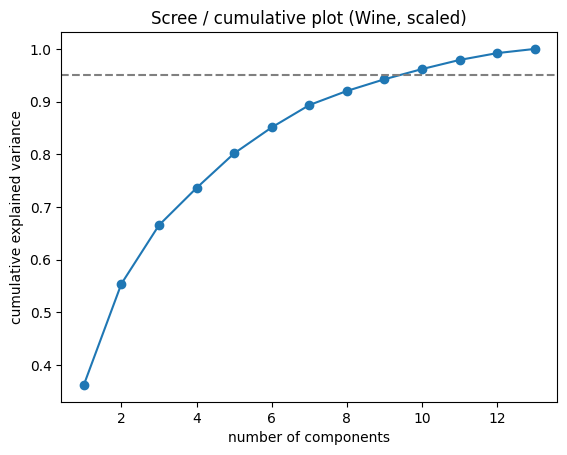

In [8]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine? **10 components (explains 96.17%)**.
2. In the lecture's PCA steps, which step did the unscaled run skip? **Step 1: Standardizing the data to zero mean and unit variance**.


In [9]:
# 1. Components needed for 95% variance on scaled Wine
cum_wine = np.cumsum(scaled.explained_variance_ratio_)
n_95 = np.argmax(cum_wine >= 0.95) + 1
print(f'Components needed for 95% variance: {n_95} (explains {cum_wine[n_95 - 1]*100:.2f}%)')

# 2. Skipped step explanation
print('Skipped step: Step 1 (Standardization/Scaling)')


Components needed for 95% variance: 10 (explains 96.17%)
Skipped step: Step 1 (Standardization/Scaling)


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [10]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: **~21 components**.  
With only 10 components, KNN accuracy will still be high around 94-95% because the top 10 components capture the main digit outline shapes.


### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796? **k = 30 (0.9778) and k = 40 (0.9759)**.
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? **It gets worse (around 0.82)**. Trees split along one axis at a time, but PCA mixes all pixels together into linear combinations making it harder for axis-aligned box cuts.


In [11]:
k_list = [2, 5, 10, 20, 30, 40, 64]
print(f"{'k':>2} | {'KNN (K=3)':>9} | {'Tree (entropy)':>14}")
print('-' * 32)

for k in k_list:
    pk = PCA(k).fit(Xtr)
    Xtr_k = pk.transform(Xtr)
    Xte_k = pk.transform(Xte)
    
    knn_acc = KNeighborsClassifier(3).fit(Xtr_k, yd_train).score(Xte_k, yd_test)
    tree_acc = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(Xtr_k, yd_train).score(Xte_k, yd_test)
    
    print(f'{k:2d} | {knn_acc:9.4f} | {tree_acc:14.4f}')


 k | KNN (K=3) | Tree (entropy)
--------------------------------
 2 |    0.5648 |         0.4944
 5 |    0.8759 |         0.7759
10 |    0.9426 |         0.8241


20 |    0.9722 |         0.8222
30 |    0.9778 |         0.8185
40 |    0.9759 |         0.8222


64 |    0.9796 |         0.8167


### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

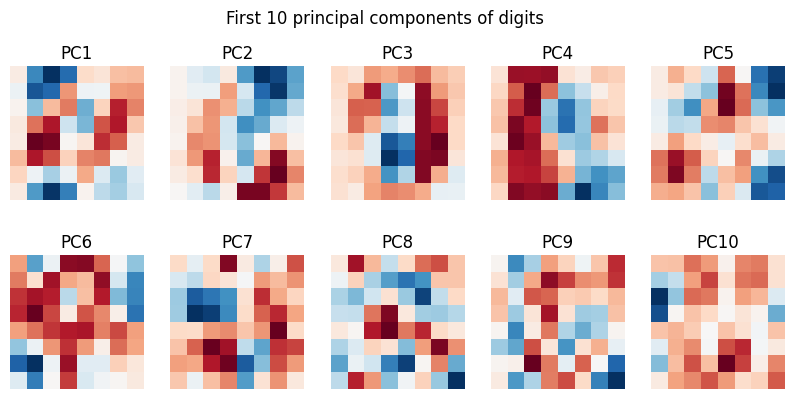

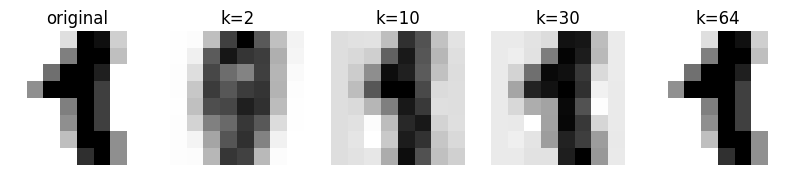

In [12]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

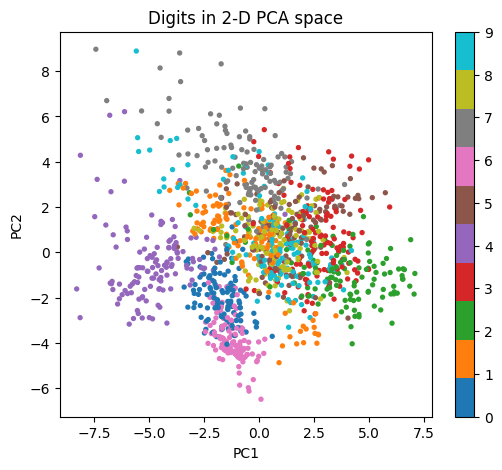

In [13]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?  
*Your answer:*  
It is data leakage because PCA and scaler learned patterns from the test set before testing. In real life we dont have test data during model training.


In [14]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [15]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns.  
(a) What is the maximum number of non-zero principal components? **min(n-1, p) = min(5, 29) = 5**.  
(b) Will 2 components capture >90% of variance? **No, 2 components only capture around 47% because word counts are very sparse across 6 sentences.**


### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest? **Sentence 0 and 3 land at the exact same point (-0.6807, -0.1170) because of shared stop words.**
4. Print the 5 words with the largest absolute weight on PC1 and PC2.


Explained variance ratio: [0.2642 0.2088]
Sum of 2 components     : 0.4731


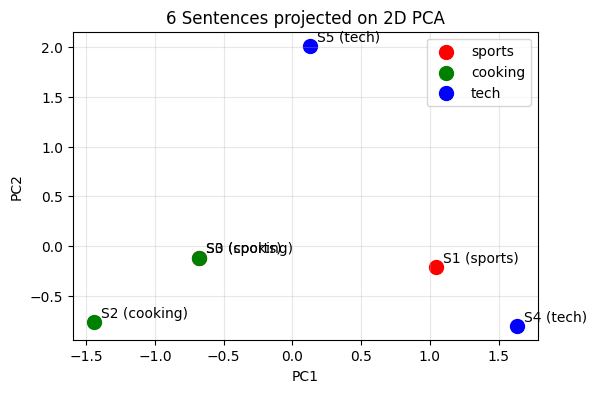


Closest pair: Sentence 0 and Sentence 3 land at exact same coordinates: [-0.6807 -0.117 ]
Top 5 words on PC1: ['a', 'and', 'the', 'processor', 'new']
Top 5 words on PC2: ['all', 'laptop', 'day', 'lasts', 'battery']


In [16]:
# 1. Fit PCA(2)
pca_text = PCA(2).fit(X_text)
print('Explained variance ratio:', pca_text.explained_variance_ratio_.round(4))
print('Sum of 2 components     :', round(pca_text.explained_variance_ratio_.sum(), 4))

# 2. Scatter plot
Z_text = pca_text.transform(X_text)
label_colors = {'sports': 'red', 'cooking': 'green', 'tech': 'blue'}

plt.figure(figsize=(6, 4))
for i in range(len(sentences)):
    plt.scatter(Z_text[i, 0], Z_text[i, 1], color=label_colors[labels[i]], s=100,
                label=labels[i] if labels[i] not in [labels[j] for j in range(i)] else '')
    plt.annotate(f'S{i} ({labels[i]})', (Z_text[i, 0] + 0.05, Z_text[i, 1] + 0.05))

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('6 Sentences projected on 2D PCA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Pair closest: S0 and S3 overlap
print('\nClosest pair: Sentence 0 and Sentence 3 land at exact same coordinates:', Z_text[0].round(4))

# 4. Top 5 words for PC1 and PC2
top5_pc1 = np.argsort(np.abs(pca_text.components_[0]))[::-1][:5]
top5_pc2 = np.argsort(np.abs(pca_text.components_[1]))[::-1][:5]
print('Top 5 words on PC1:', [vocab[i] for i in top5_pc1])
print('Top 5 words on PC2:', [vocab[i] for i in top5_pc2])


## Part 6: Reflection (write 2–3 lines each)

1. **In your own words: what does PCA keep and what does it throw away?**  
pca keeps the directions with maximum variance where data spreads most. it throws away components with small variance thinking they are just noise.

2. **Why must we standardize before PCA? Give the Wine evidence.**  
we must standardize so all features have equal scale. on wine dataset without scaling proline had huge variance and pc1 took 99.8% alone, ignoring all other 12 features.

3. **Digits: pick the k you would deploy and justify (accuracy vs. size).**  
i will pick k=30 components. it gives 97.78% accuracy which is almost same as full 64 pixels (97.96%) but saves more than half the memory and computation.

4. **PCA helped KNN but not the tree. What does this say about when to use PCA?**  
knn works on distance so removing noise helps it, but decision tree cuts on single axis. pca mixes features together making diagonal cuts hard for tree to split.

5. **PCA is unsupervised; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)**  
pca only cares about large variance not class labels. sometimes the direction with biggest variance has classes overlapping, so it might mix up classes.

6. **Capstone link (Milestone, Week 9): will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.**  
yes if our project has many correlated numeric features we can use pca with 95% variance cut. if dataset has few or categorical features then pca is not needed.


*Submit this notebook to GitHub under `labs/week9_pca/`.*